<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/Lab%20Exp/CO1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer-Genre matrix R (6x5):
 [[4. 5. 3. 5. 5.]
 [2. 3. 3. 3. 5.]
 [4. 3. 5. 2. 4.]
 [2. 4. 5. 1. 4.]
 [2. 5. 4. 1. 1.]
 [3. 3. 2. 4. 4.]]

Genre-Book matrix G (5x4):
 [[0.37 0.46 0.79 0.2 ]
 [0.51 0.59 0.05 0.61]
 [0.17 0.07 0.95 0.97]
 [0.81 0.3  0.1  0.68]
 [0.44 0.12 0.5  0.03]]

Dot product (Cust1 . Cust2): 72.0

Score matrix S = R @ G (6x4):
 [[10.79  7.1   9.26 10.31]
 [ 7.41  4.4   7.38  7.33]
 [ 7.24  5.04 10.26  8.96]
 [ 6.2   4.41  8.63  8.49]
 [ 5.22  4.57  6.23  8.04]
 [ 7.98  4.97  6.82  7.21]]

Transpose of R (5x6):
 [[4. 2. 4. 2. 2. 3.]
 [5. 3. 3. 4. 5. 3.]
 [3. 3. 5. 5. 4. 2.]
 [5. 3. 2. 1. 1. 4.]
 [5. 5. 4. 4. 1. 4.]]

Inverse of the 5x5 sub-matrix:
 [[ 1.017 -1.776 -0.034  1.207 -0.897]
 [ 0.759 -1.138 -0.517  1.103 -0.448]
 [-1.31   1.966  0.621 -1.724  1.138]
 [-1.276  2.414  0.552 -2.31   1.345]
 [ 0.69  -1.034 -0.379  1.276 -0.862]]

Pseudo-inverse of full R (5x6):
 [[ 1.325 -1.175  0.2    0.65  -0.75  -0.85 ]
 [ 1.005 -0.657 -0.33   0.658 -0.331 -0.68 ]
 [-1.7

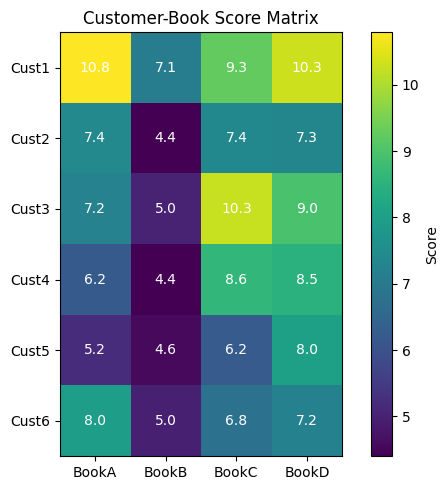

In [ ]:
"""Experiment 1: Vector and Matrix Operations for Deep Learning"""
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
customers = [f"Cust{i+1}" for i in range(6)]
genres = ["Fiction", "Mystery", "SciFi", "Romance", "History"]
books = ["BookA", "BookB", "BookC", "BookD"]

# ---- Task 1: build matrices --------------------------------------------
R = np.random.randint(1, 6, size=(6, 5)).astype(float)   # customer x genre (ratings 1-5)
G = np.round(np.random.rand(5, 4), 2)                     # genre x book (weights 0-1)
print("Customer-Genre matrix R (6x5):\n", R)
print("\nGenre-Book matrix G (5x4):\n", G)

# ---- Task 2: core operations -------------------------------------------
print("\nDot product (Cust1 . Cust2):", np.dot(R[0], R[1]))
S = R @ G                                                 # score matrix (6x4)
print("\nScore matrix S = R @ G (6x4):\n", np.round(S, 2))
print("\nTranspose of R (5x6):\n", R.T)

R_sq = R[:5]                                              # inverse needs a square matrix
if np.linalg.det(R_sq) != 0:
    print("\nInverse of the 5x5 sub-matrix:\n", np.round(np.linalg.inv(R_sq), 3))
print("\nPseudo-inverse of full R (5x6):\n", np.round(np.linalg.pinv(R), 3))

print("\nElement-wise add (R+1):\n", R + 1)
print("Element-wise multiply (R*R):\n", R * R)
print("Element-wise divide (R/5):\n", R / 5)

# ---- Task 3: cosine similarity -----------------------------------------
norms = np.linalg.norm(R, axis=1, keepdims=True)
cos_sim = (R @ R.T) / (norms @ norms.T)
print("\nCosine similarity matrix:\n", np.round(cos_sim, 3))

masked = cos_sim.copy()
np.fill_diagonal(masked, -1)                              # ignore self-similarity
i, j = np.unravel_index(np.argmax(masked), masked.shape)
print(f"\nMost similar customers: {customers[i]} and {customers[j]} "
      f"(cosine = {cos_sim[i, j]:.3f})")

# ---- Task 4: dense layer y = Wx + b ------------------------------------
x = R[0]                         # one customer's rating vector (5,)
W = G.T                          # weights (4 books x 5 genres)
b = np.array([0.1, -0.2, 0.05, 0.0])

y_manual = np.zeros(4)           # explicit loops: y_i = sum_j W_ij x_j + b_i
for r in range(4):
    total = 0.0
    for c in range(5):
        total += W[r, c] * x[c]
    y_manual[r] = total + b[r]

y_numpy = W @ x + b
print("\nDense layer output (manual):", np.round(y_manual, 3))
print("Dense layer output (W@x+b) :", np.round(y_numpy, 3))
print("Match:", np.allclose(y_manual, y_numpy))

# ---- Task 5: heatmap ----------------------------------------------------
plt.figure(figsize=(6, 5))
plt.imshow(S, cmap="viridis")
plt.colorbar(label="Score")
plt.xticks(range(4), books)
plt.yticks(range(6), customers)
for r in range(S.shape[0]):
    for c in range(S.shape[1]):
        plt.text(c, r, f"{S[r, c]:.1f}", ha="center", va="center", color="white")
plt.title("Customer-Book Score Matrix")
plt.tight_layout()
plt.show()

       Haemoglobin     RBC  Glucose  Cholesterol     BMI
count       200.00  200.00   200.00       200.00  200.00
mean         13.89    4.79   100.54       190.37   25.04
std           1.45    0.50    18.89        33.17    3.65
min           9.33    3.45    47.47        99.54   16.38
25%          12.90    4.49    87.96       168.59   22.40
50%          13.89    4.76   100.40       190.59   25.22
75%          14.89    5.08   112.88       213.92   27.31
max          17.94    6.24   147.52       267.63   34.12

Covariance matrix:
              Haemoglobin    RBC  Glucose  Cholesterol    BMI
Haemoglobin        1.000  0.839    0.026        0.024  0.003
RBC                0.839  1.000    0.014        0.046  0.069
Glucose            0.026  0.014    1.000        0.367  0.477
Cholesterol        0.024  0.046    0.367        1.000  0.450
BMI                0.003  0.069    0.477        0.450  1.000

Correlation matrix:
              Haemoglobin    RBC  Glucose  Cholesterol    BMI
Haemoglobin      

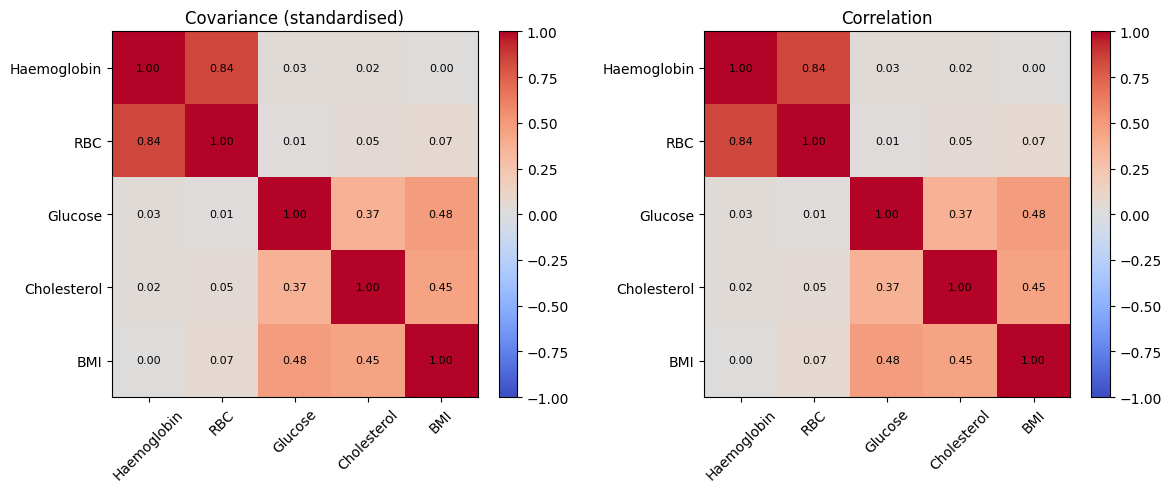


Eigenvalues: [1.9275 1.7768 0.6354 0.5044 0.156 ]
Eigenvectors (columns):
                PC1    PC2    PC3    PC4    PC5
Haemoglobin -0.446  0.549  0.028  0.078  0.702
RBC         -0.466  0.531 -0.011 -0.069 -0.704
Glucose     -0.428 -0.376  0.651  0.498 -0.059
Cholesterol -0.429 -0.354 -0.754  0.349 -0.005
BMI         -0.465 -0.387  0.081 -0.787  0.092


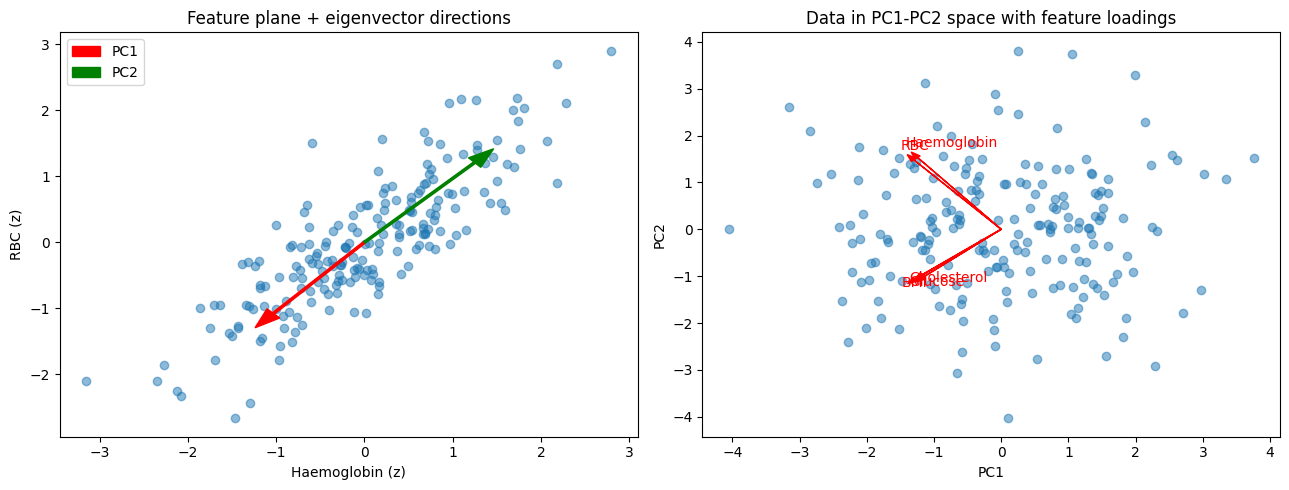

PC1: 38.55%  (cumulative 38.55%)
PC2: 35.54%  (cumulative 74.08%)
PC3: 12.71%  (cumulative 86.79%)
PC4: 10.09%  (cumulative 96.88%)
PC5: 3.12%  (cumulative 100.00%)


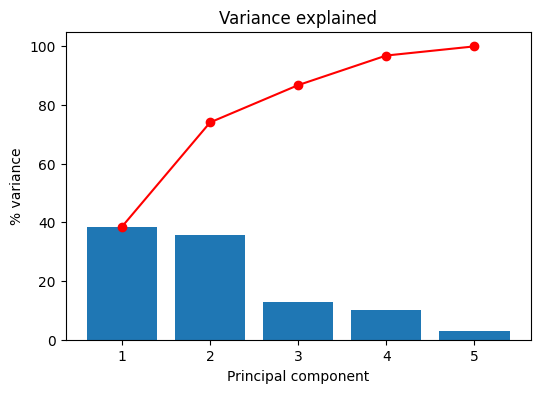

In [ ]:
"""Experiment 2: Covariance, Eigenvalues and Eigenvectors Analysis"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
cols = ["Haemoglobin", "RBC", "Glucose", "Cholesterol", "BMI"]

# Synthetic correlated blood data (Hb and RBC strongly linked, glucose/chol/BMI linked)
mean = [14, 4.8, 100, 190, 25]
sd = np.array([1.5, 0.5, 20, 35, 4])
corr_true = np.array([
    [1.0, 0.85, 0.05, 0.05, 0.05],
    [0.85, 1.0, 0.05, 0.05, 0.05],
    [0.05, 0.05, 1.0, 0.45, 0.55],
    [0.05, 0.05, 0.45, 1.0, 0.50],
    [0.05, 0.05, 0.55, 0.50, 1.0]])
cov_true = corr_true * np.outer(sd, sd)
df = pd.DataFrame(np.random.multivariate_normal(mean, cov_true, 200), columns=cols)
print(df.describe().round(2))

# ---- Task 1: standardise -------------------------------------------------
Z = (df - df.mean()) / df.std(ddof=1)

# ---- Task 2: covariance & correlation -----------------------------------
cov = np.cov(Z.values, rowvar=False)
corr = np.corrcoef(Z.values, rowvar=False)
print("\nCovariance matrix:\n", pd.DataFrame(cov, cols, cols).round(3))
print("\nCorrelation matrix:\n", pd.DataFrame(corr, cols, cols).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, M, t in zip(ax, [cov, corr], ["Covariance (standardised)", "Correlation"]):
    im = a.imshow(M, cmap="coolwarm", vmin=-1, vmax=1)
    a.set_xticks(range(5)); a.set_xticklabels(cols, rotation=45)
    a.set_yticks(range(5)); a.set_yticklabels(cols)
    for r in range(5):
        for c in range(5):
            a.text(c, r, f"{M[r, c]:.2f}", ha="center", va="center", fontsize=8)
    a.set_title(t)
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

# ---- Task 3: eigen-decomposition (eigh for symmetric matrices) ----------
vals, vecs = np.linalg.eigh(cov)
order = np.argsort(vals)[::-1]
vals, vecs = vals[order], vecs[:, order]
print("\nEigenvalues:", np.round(vals, 4))
print("Eigenvectors (columns):\n", pd.DataFrame(vecs, cols,
      [f"PC{i+1}" for i in range(5)]).round(3))

# ---- Task 4: 2-D plot with eigenvector arrows ---------------------------
scores = Z.values @ vecs[:, :2]               # data projected on PC1, PC2
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# (a) feature plane Haemoglobin vs RBC with eigenvector components as arrows
ax[0].scatter(Z["Haemoglobin"], Z["RBC"], alpha=0.5)
for k, c in zip(range(2), ["red", "green"]):
    v = vecs[[0, 1], k] * np.sqrt(vals[k]) * 2
    ax[0].arrow(0, 0, v[0], v[1], color=c, width=0.03, head_width=0.2,
                length_includes_head=True, label=f"PC{k+1}")
ax[0].set_xlabel("Haemoglobin (z)"); ax[0].set_ylabel("RBC (z)")
ax[0].set_title("Feature plane + eigenvector directions"); ax[0].legend()

# (b) PC space with original features as arrows (loadings)
ax[1].scatter(scores[:, 0], scores[:, 1], alpha=0.5)
for i, name in enumerate(cols):
    ax[1].arrow(0, 0, vecs[i, 0] * 3, vecs[i, 1] * 3, color="red",
                head_width=0.1, length_includes_head=True)
    ax[1].text(vecs[i, 0] * 3.2, vecs[i, 1] * 3.2, name, color="red")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
ax[1].set_title("Data in PC1-PC2 space with feature loadings")
plt.tight_layout(); plt.show()

# ---- Task 5: variance explained -----------------------------------------
pct = vals / vals.sum() * 100
for i, p in enumerate(pct):
    print(f"PC{i+1}: {p:.2f}%  (cumulative {pct[:i+1].sum():.2f}%)")
plt.figure(figsize=(6, 4))
plt.bar(range(1, 6), pct); plt.plot(range(1, 6), np.cumsum(pct), "ro-")
plt.xlabel("Principal component"); plt.ylabel("% variance")
plt.title("Variance explained"); plt.show()

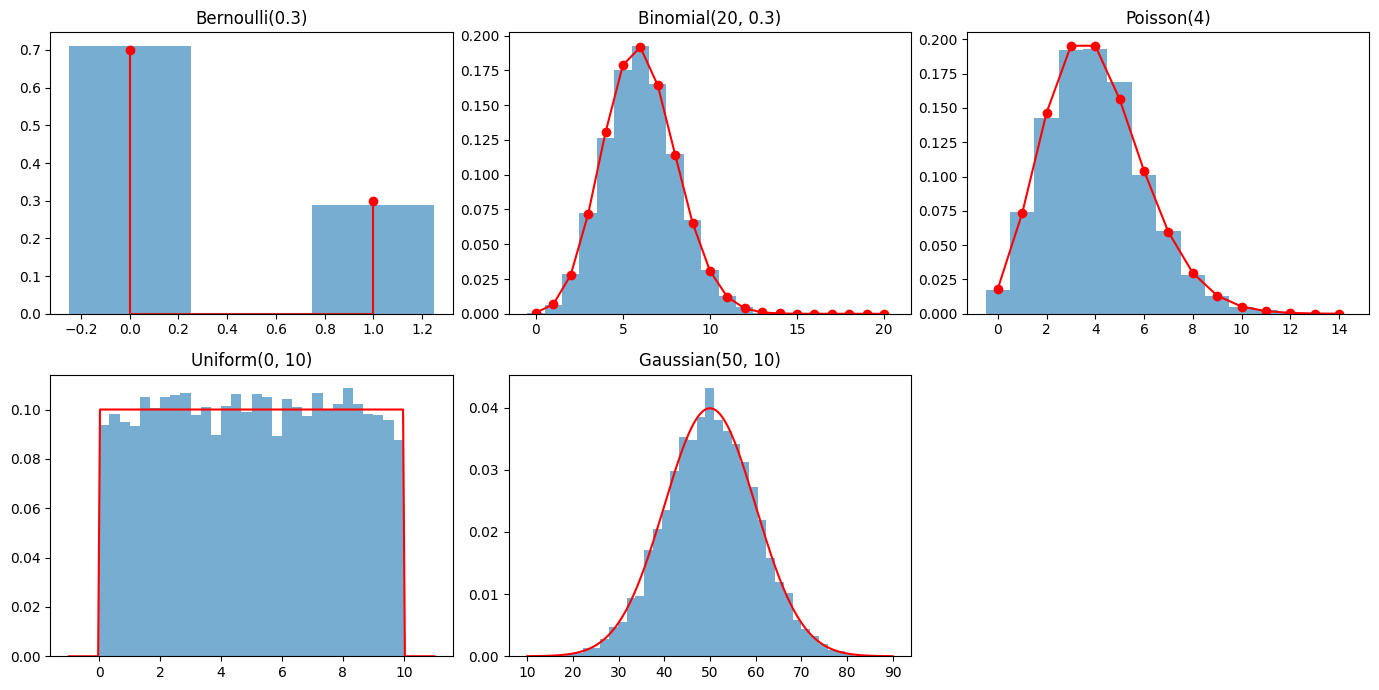

P(Disease | Positive) = 0.0876  (8.76%)
Positives: 10859, of which diseased: 932
Empirical P(Disease | Positive) = 0.0858  vs theoretical 0.0876


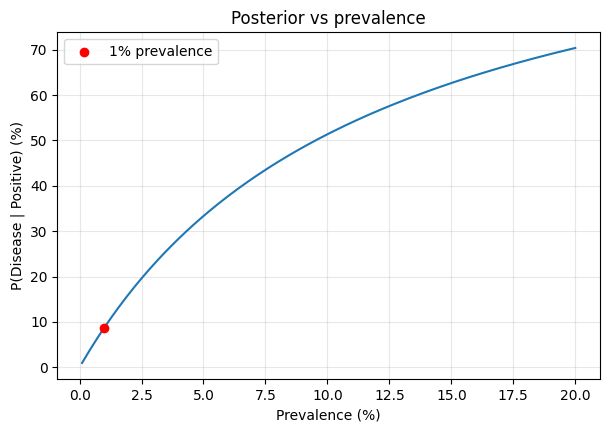

In [ ]:
"""Experiment 3: Probability Distributions and Bayes' Theorem"""
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)
N = 10000

# ---- Task 1: distributions ----------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
ax = ax.ravel()

p = 0.3
s = stats.bernoulli.rvs(p, size=N)
ax[0].hist(s, bins=[-0.5, 0.5, 1.5], density=True, rwidth=0.5, alpha=0.6, label="samples")
ax[0].stem([0, 1], stats.bernoulli.pmf([0, 1], p), "r", label="PMF"); ax[0].set_title("Bernoulli(0.3)")

n = 20
s = stats.binom.rvs(n, p, size=N)
k = np.arange(0, n + 1)
ax[1].hist(s, bins=np.arange(-0.5, n + 1.5), density=True, alpha=0.6)
ax[1].plot(k, stats.binom.pmf(k, n, p), "ro-"); ax[1].set_title("Binomial(20, 0.3)")

lam = 4
s = stats.poisson.rvs(lam, size=N)
k = np.arange(0, 15)
ax[2].hist(s, bins=np.arange(-0.5, 15.5), density=True, alpha=0.6)
ax[2].plot(k, stats.poisson.pmf(k, lam), "ro-"); ax[2].set_title("Poisson(4)")

s = stats.uniform.rvs(0, 10, size=N)
x = np.linspace(-1, 11, 200)
ax[3].hist(s, bins=30, density=True, alpha=0.6)
ax[3].plot(x, stats.uniform.pdf(x, 0, 10), "r"); ax[3].set_title("Uniform(0, 10)")

s = stats.norm.rvs(50, 10, size=N)          # e.g. patient age
x = np.linspace(10, 90, 200)
ax[4].hist(s, bins=40, density=True, alpha=0.6)
ax[4].plot(x, stats.norm.pdf(x, 50, 10), "r"); ax[4].set_title("Gaussian(50, 10)")
ax[5].axis("off")
plt.tight_layout(); plt.show()

# ---- Task 2: Bayes' theorem ---------------------------------------------
prev, sens, spec = 0.01, 0.95, 0.90

def posterior(prev, sens=sens, spec=spec):
    p_pos = sens * prev + (1 - spec) * (1 - prev)       # total probability
    return sens * prev / p_pos

post = posterior(prev)
print(f"P(Disease | Positive) = {post:.4f}  ({post*100:.2f}%)")

# ---- Task 3: simulation of 100,000 patients -----------------------------
M = 100_000
disease = np.random.rand(M) < prev
test_pos = np.where(disease, np.random.rand(M) < sens, np.random.rand(M) < (1 - spec))
emp = disease[test_pos].mean()
print(f"Positives: {test_pos.sum()}, of which diseased: {disease[test_pos].sum()}")
print(f"Empirical P(Disease | Positive) = {emp:.4f}  vs theoretical {post:.4f}")

# ---- Task 4: posterior vs prevalence ------------------------------------
prevs = np.linspace(0.001, 0.20, 200)
plt.figure(figsize=(7, 4.5))
plt.plot(prevs * 100, posterior(prevs) * 100)
plt.scatter([1], [post * 100], color="red", zorder=3, label="1% prevalence")
plt.xlabel("Prevalence (%)"); plt.ylabel("P(Disease | Positive) (%)")
plt.title("Posterior vs prevalence"); plt.grid(alpha=0.3); plt.legend(); plt.show()

True P: [0.5 0.3 0.2]

Entropy H(P) = 1.0297 nats (scipy: 1.0297)

Model           CE        KL      H+KL
A           1.0361    0.0064    1.0361   CE == H+KL: True
B           1.1217    0.0920    1.1217   CE == H+KL: True
Better model (lower KL): A

Model A: KL(P||Q) = 0.0064, KL(Q||P) = 0.0065

Model B: KL(P||Q) = 0.0920, KL(Q||P) = 0.0851


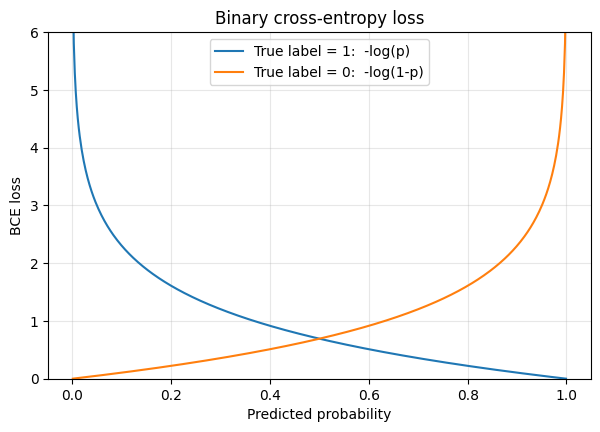

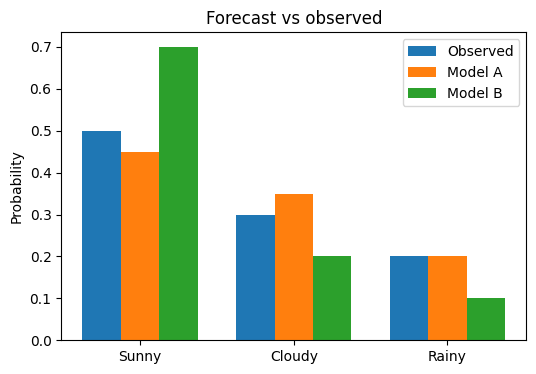

In [ ]:
"""Experiment 4: Entropy, Cross-Entropy and KL Divergence"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

labels = ["Sunny", "Cloudy", "Rainy"]
counts = np.array([15, 9, 6])                  # 30 observed days
P = counts / counts.sum()                      # true distribution
Q1 = np.array([0.45, 0.35, 0.20])              # Model A
Q2 = np.array([0.70, 0.20, 0.10])              # Model B
print("True P:", P)

# ---- Task 1: entropy -----------------------------------------------------
H = -np.sum(P * np.log(P))
print(f"\nEntropy H(P) = {H:.4f} nats (scipy: {entropy(P):.4f})")

def cross_entropy(p, q): return -np.sum(p * np.log(q))
def kl(p, q): return np.sum(p * np.log(p / q))

# ---- Task 2 & 3: CE, KL, identity ---------------------------------------
print(f"\n{'Model':8}{'CE':>10}{'KL':>10}{'H+KL':>10}")
for name, Q in [("A", Q1), ("B", Q2)]:
    ce, d = cross_entropy(P, Q), kl(P, Q)
    print(f"{name:8}{ce:10.4f}{d:10.4f}{H + d:10.4f}   CE == H+KL: {np.isclose(ce, H + d)}")
better = "A" if kl(P, Q1) < kl(P, Q2) else "B"
print("Better model (lower KL):", better)

# ---- Task 4: asymmetry ---------------------------------------------------
for name, Q in [("A", Q1), ("B", Q2)]:
    print(f"\nModel {name}: KL(P||Q) = {kl(P, Q):.4f}, KL(Q||P) = {kl(Q, P):.4f}")

# ---- Task 5: binary cross-entropy vs predicted probability --------------
p_hat = np.linspace(0.001, 0.999, 500)
plt.figure(figsize=(7, 4.5))
plt.plot(p_hat, -np.log(p_hat), label="True label = 1:  -log(p)")
plt.plot(p_hat, -np.log(1 - p_hat), label="True label = 0:  -log(1-p)")
plt.xlabel("Predicted probability"); plt.ylabel("BCE loss"); plt.ylim(0, 6)
plt.title("Binary cross-entropy loss"); plt.legend(); plt.grid(alpha=0.3); plt.show()

x = np.arange(3); w = 0.25
plt.figure(figsize=(6, 4))
plt.bar(x - w, P, w, label="Observed"); plt.bar(x, Q1, w, label="Model A"); plt.bar(x + w, Q2, w, label="Model B")
plt.xticks(x, labels); plt.ylabel("Probability"); plt.legend(); plt.title("Forecast vs observed"); plt.show()

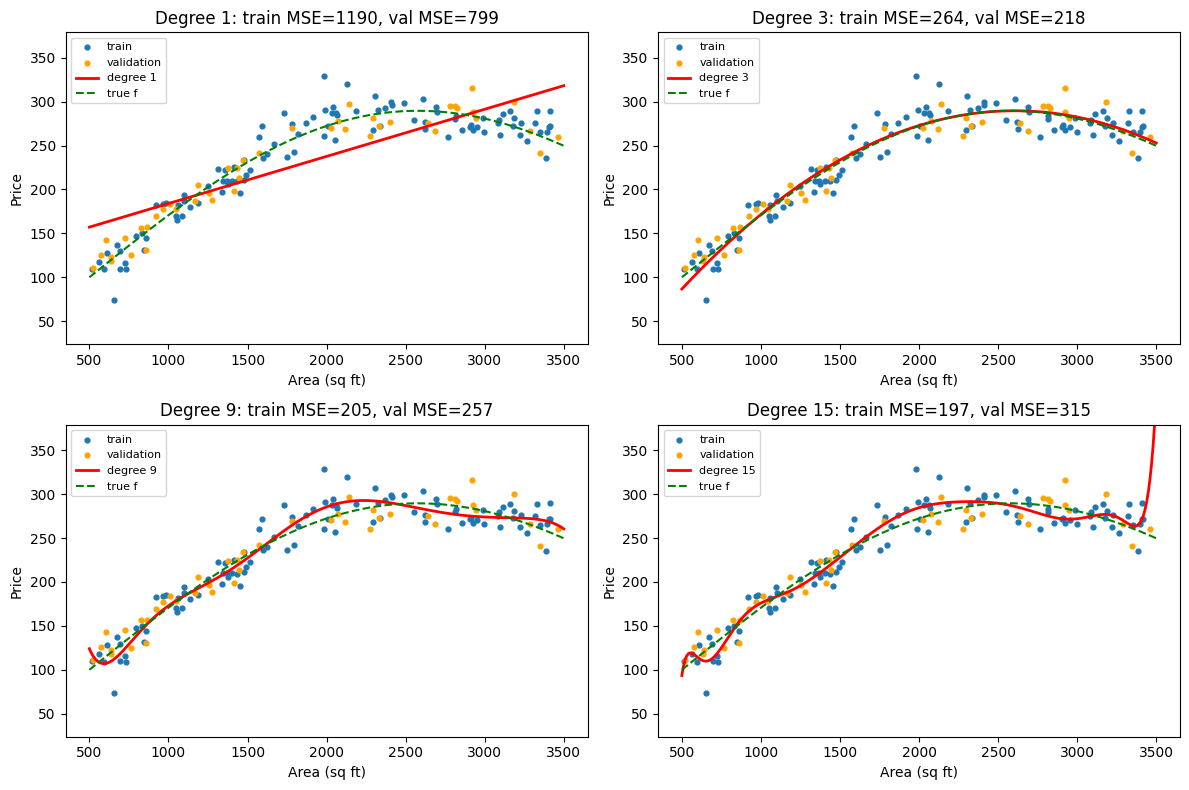

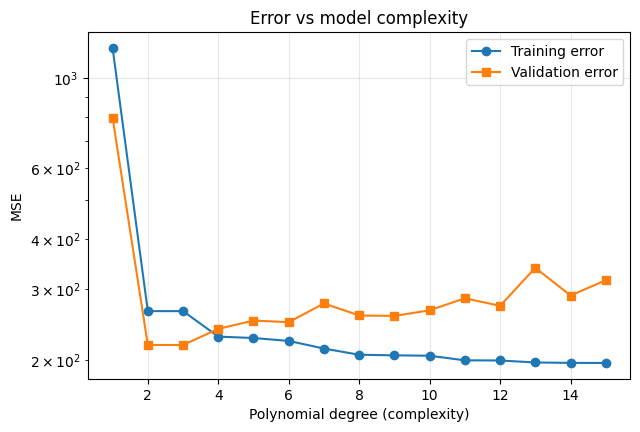

Degree      Bias^2    Variance   Bias^2+Var
     1       729.4        22.8        752.2
     3         6.8         9.8         16.7
     9        46.9        18.8         65.7
    15        55.7        45.6        101.2


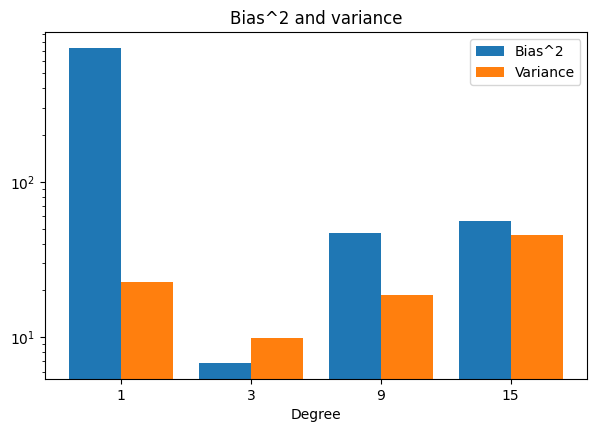


Best degree by validation error: 3 (val MSE = 217.8)
Justification: lowest validation error; lower degrees underfit (high bias), higher degrees overfit (high variance, train error << val error).


In [ ]:
"""Experiment 5: Bias-Variance, Overfitting and Underfitting Analysis"""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.RandomState(42)

def true_fn(area):                                   # hidden non-linear relationship
    u = (area - 500) / 3000
    return 100 + 150 * np.sin(2.5 * u) + 60 * u

area = rng.uniform(500, 3500, 150)
price = true_fn(area) + rng.normal(0, 15, 150)       # noisy price (in lakhs)
X = area.reshape(-1, 1)
X_tr, X_val, y_tr, y_val = train_test_split(X, price, test_size=0.3, random_state=1)
grid = np.linspace(500, 3500, 300).reshape(-1, 1)

def make_model(d):
    return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())

# ---- Tasks 1 & 2: fit degrees 1, 3, 9, 15 -------------------------------
fig, ax = plt.subplots(2, 2, figsize=(12, 8)); ax = ax.ravel()
for a, d in zip(ax, [1, 3, 9, 15]):
    m = make_model(d).fit(X_tr, y_tr)
    a.scatter(X_tr, y_tr, s=12, label="train"); a.scatter(X_val, y_val, s=12, c="orange", label="validation")
    a.plot(grid, m.predict(grid), "r", lw=2, label=f"degree {d}")
    a.plot(grid, true_fn(grid.ravel()), "g--", label="true f")
    a.set_ylim(price.min() - 50, price.max() + 50)
    a.set_title(f"Degree {d}: train MSE={mean_squared_error(y_tr, m.predict(X_tr)):.0f}, "
                f"val MSE={mean_squared_error(y_val, m.predict(X_val)):.0f}")
    a.set_xlabel("Area (sq ft)"); a.set_ylabel("Price"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Task 3: error vs complexity ----------------------------------------
degrees = range(1, 16)
tr_err, val_err = [], []
for d in degrees:
    m = make_model(d).fit(X_tr, y_tr)
    tr_err.append(mean_squared_error(y_tr, m.predict(X_tr)))
    val_err.append(mean_squared_error(y_val, m.predict(X_val)))
plt.figure(figsize=(7, 4.5))
plt.plot(degrees, tr_err, "o-", label="Training error")
plt.plot(degrees, val_err, "s-", label="Validation error")
plt.yscale("log"); plt.xlabel("Polynomial degree (complexity)"); plt.ylabel("MSE")
plt.title("Error vs model complexity"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# ---- Task 4: bias^2 and variance via bootstrap --------------------------
B = 200
x_test = np.linspace(600, 3400, 100).reshape(-1, 1)
f_true = true_fn(x_test.ravel())
print(f"{'Degree':>6}{'Bias^2':>12}{'Variance':>12}{'Bias^2+Var':>13}")
bias2_list, var_list = [], []
for d in [1, 3, 9, 15]:
    preds = np.zeros((B, len(x_test)))
    for b in range(B):
        idx = rng.choice(len(X_tr), len(X_tr), replace=True)       # bootstrap resample
        preds[b] = make_model(d).fit(X_tr[idx], y_tr[idx]).predict(x_test)
    mean_pred = preds.mean(axis=0)
    bias2 = np.mean((mean_pred - f_true) ** 2)
    var = np.mean(preds.var(axis=0))
    bias2_list.append(bias2); var_list.append(var)
    print(f"{d:>6}{bias2:12.1f}{var:12.1f}{bias2 + var:13.1f}")

plt.figure(figsize=(7, 4.5))
xs = np.arange(4)
plt.bar(xs - 0.2, bias2_list, 0.4, label="Bias^2"); plt.bar(xs + 0.2, var_list, 0.4, label="Variance")
plt.xticks(xs, ["1", "3", "9", "15"]); plt.yscale("log"); plt.xlabel("Degree")
plt.title("Bias^2 and variance"); plt.legend(); plt.show()

# ---- Task 5: best degree -------------------------------------------------
best = list(degrees)[int(np.argmin(val_err))]
print(f"\nBest degree by validation error: {best} (val MSE = {min(val_err):.1f})")
print("Justification: lowest validation error; lower degrees underfit (high bias), "
      "higher degrees overfit (high variance, train error << val error).")

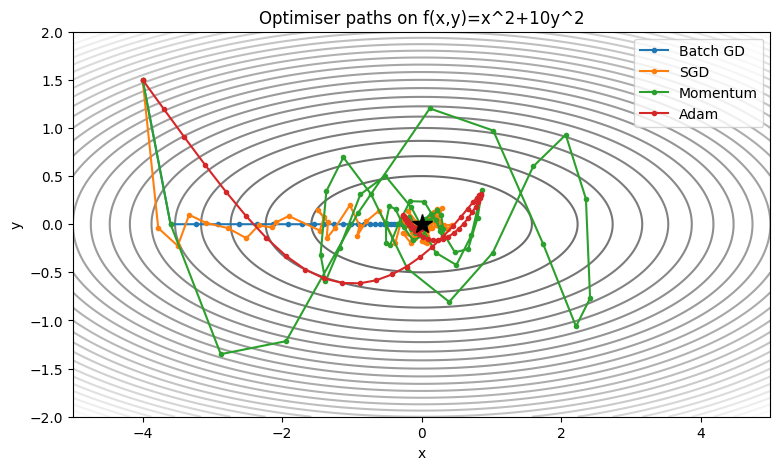

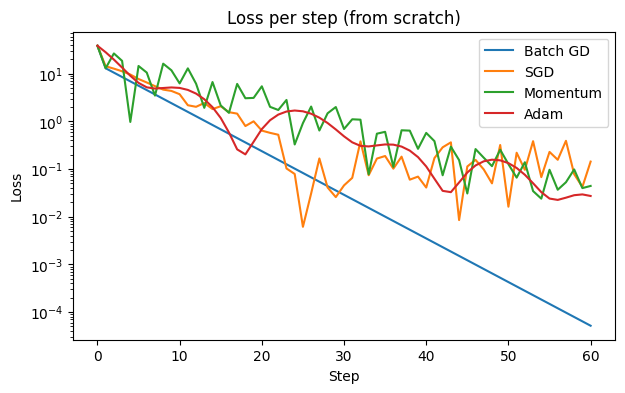

SGD (lr=0.01)          final train loss 0.0427 | val loss 0.0491 | 10.4s
SGD+Momentum (0.9)     final train loss 0.0391 | val loss 0.0473 | 9.7s
Adam (lr=0.001)        final train loss 0.0388 | val loss 0.0467 | 10.2s


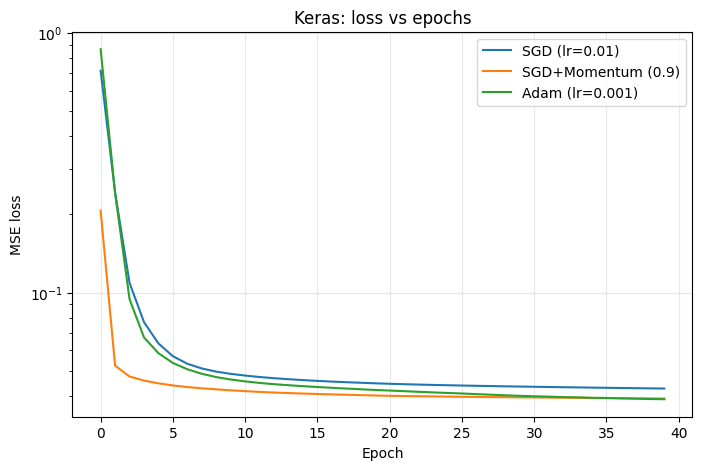

SGD lr=0.0001   final loss=0.8414  -> slow/unstable
SGD lr=0.001    final loss=0.0776  -> ok
SGD lr=0.01     final loss=0.0447  -> ok
SGD lr=0.1      final loss=0.0404  -> ok
SGD lr=1.0      final loss=nan  -> DIVERGED
SGD lr=5.0      final loss=nan  -> DIVERGED
Adam lr=1e-05    final loss=0.9701  -> slow/unstable
Adam lr=0.0001   final loss=0.0619  -> ok
Adam lr=0.001    final loss=0.0391  -> ok
Adam lr=0.01     final loss=0.0317  -> ok
Adam lr=0.1      final loss=0.0534  -> ok
Adam lr=1.0      final loss=1.0078  -> slow/unstable


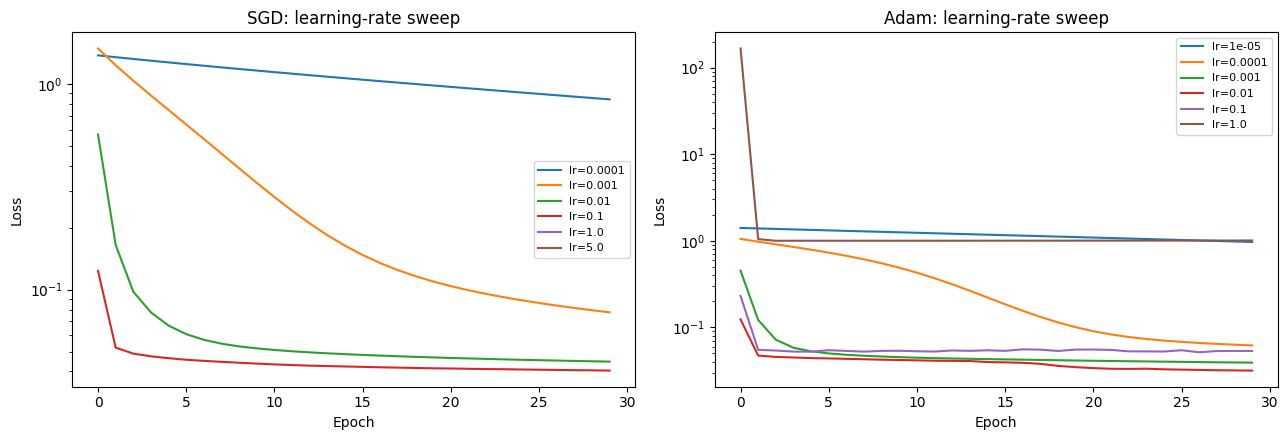

In [ ]:
"""Experiment 6: Gradient Descent, SGD, Momentum and Adam Comparison"""
import time
import numpy as np
import matplotlib.pyplot as plt

# =========================== PART A: from scratch ===========================
# Loss surface: elongated bowl  f(x, y) = x^2 + 10 y^2   (minimum at (0, 0))
def f(p):    return p[0] ** 2 + 10 * p[1] ** 2
def grad(p): return np.array([2 * p[0], 20 * p[1]])

start = np.array([-4.0, 1.5])
steps = 60
rng = np.random.RandomState(0)

def batch_gd(lr=0.05):
    p, path = start.copy(), [start.copy()]
    for _ in range(steps):
        p = p - lr * grad(p); path.append(p.copy())
    return np.array(path)

def sgd(lr=0.05, noise=2.0):                      # noisy gradient mimics a mini-batch
    p, path = start.copy(), [start.copy()]
    for _ in range(steps):
        g = grad(p) + rng.normal(0, noise, 2)
        p = p - lr * g; path.append(p.copy())
    return np.array(path)

def momentum(lr=0.05, beta=0.9):
    p, v, path = start.copy(), np.zeros(2), [start.copy()]
    for _ in range(steps):
        v = beta * v - lr * grad(p)
        p = p + v; path.append(p.copy())
    return np.array(path)

def adam(lr=0.3, b1=0.9, b2=0.999, eps=1e-8):
    p, m, v, path = start.copy(), np.zeros(2), np.zeros(2), [start.copy()]
    for t in range(1, steps + 1):
        g = grad(p)
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g ** 2
        p = p - lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)
        path.append(p.copy())
    return np.array(path)

paths = {"Batch GD": batch_gd(), "SGD": sgd(), "Momentum": momentum(), "Adam": adam()}

# Task 2: contour plot with paths
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-2, 2, 200))
zz = xx ** 2 + 10 * yy ** 2
plt.figure(figsize=(9, 5))
plt.contour(xx, yy, zz, levels=30, cmap="gray", alpha=0.6)
for (name, pth), c in zip(paths.items(), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    plt.plot(pth[:, 0], pth[:, 1], "o-", ms=3, color=c, label=name)
plt.plot(0, 0, "k*", ms=15)
plt.legend(); plt.title("Optimiser paths on f(x,y)=x^2+10y^2"); plt.xlabel("x"); plt.ylabel("y"); plt.show()

plt.figure(figsize=(7, 4))
for name, pth in paths.items():
    plt.plot([f(p) for p in pth], label=name)
plt.yscale("log"); plt.xlabel("Step"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss per step (from scratch)"); plt.show()

# =========================== PART B: Keras ==================================
import tensorflow as tf
from tensorflow import keras
tf.random.set_seed(42); np.random.seed(42)

# Synthetic delivery data
n = 2000
distance = np.random.uniform(1, 30, n)
traffic = np.random.uniform(0, 10, n)
weight = np.random.uniform(1, 50, n)
tod = np.random.uniform(0, 24, n)
rush = np.exp(-((tod - 9) ** 2) / 8) + np.exp(-((tod - 18) ** 2) / 8)
time_min = 10 + 2.0 * distance + 1.5 * traffic * (1 + rush) + 0.3 * weight + np.random.normal(0, 3, n)

X = np.column_stack([distance, traffic, weight, tod])
X = (X - X.mean(0)) / X.std(0)
y = (time_min - time_min.mean()) / time_min.std()
split = int(0.8 * n)
X_tr, X_te, y_tr, y_te = X[:split], X[split:], y[:split], y[split:]

def build():
    return keras.Sequential([keras.layers.Input((4,)),
                             keras.layers.Dense(32, activation="relu"),
                             keras.layers.Dense(16, activation="relu"),
                             keras.layers.Dense(1)])

def train(opt, epochs=40):
    m = build(); m.compile(optimizer=opt, loss="mse")
    t0 = time.time()
    h = m.fit(X_tr, y_tr, validation_data=(X_te, y_te), epochs=epochs, batch_size=32, verbose=0)
    return h.history, time.time() - t0

configs = {
    "SGD (lr=0.01)": keras.optimizers.SGD(0.01),
    "SGD+Momentum (0.9)": keras.optimizers.SGD(0.01, momentum=0.9),
    "Adam (lr=0.001)": keras.optimizers.Adam(0.001),
}
plt.figure(figsize=(8, 5))
for name, opt in configs.items():
    hist, t = train(opt)
    plt.plot(hist["loss"], label=f"{name}")
    print(f"{name:22} final train loss {hist['loss'][-1]:.4f} | val loss {hist['val_loss'][-1]:.4f} | {t:.1f}s")
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.yscale("log")
plt.title("Keras: loss vs epochs"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# Task 5: learning-rate sweep
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (opt_name, make_opt, lrs) in zip(ax, [
        ("SGD", lambda lr: keras.optimizers.SGD(lr), [0.0001, 0.001, 0.01, 0.1, 1.0, 5.0]),
        ("Adam", lambda lr: keras.optimizers.Adam(lr), [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0])]):
    for lr in lrs:
        hist, _ = train(make_opt(lr), epochs=30)
        final = hist["loss"][-1]
        status = "DIVERGED" if (not np.isfinite(final) or final > 10) else ("slow/unstable" if final > 0.2 else "ok")
        print(f"{opt_name} lr={lr:<8} final loss={final:.4f}  -> {status}")
        a.plot(hist["loss"], label=f"lr={lr}")
    a.set_yscale("log"); a.set_title(f"{opt_name}: learning-rate sweep")
    a.set_xlabel("Epoch"); a.set_ylabel("Loss"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()